In [50]:
import glob
import re
import os  


import numpy as np
from scipy import stats
from matplotlib import pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import math
import pandas as pd
from utils import Graph
from mpl_toolkits.mplot3d import Axes3D
import itertools



os.chdir("/home/aidan/TRANSLATE/py/recombination_data")

# Load the data from the CSV file 
data = np.genfromtxt('ICARUS_TPC.csv', delimiter=',')
r_k = data[:, 0]
prob = data[:, 1]
k_exp = 4.86e-05
k = k_exp / (1.396)




## Recombination Plots at 500V/cm and 200V/cm 

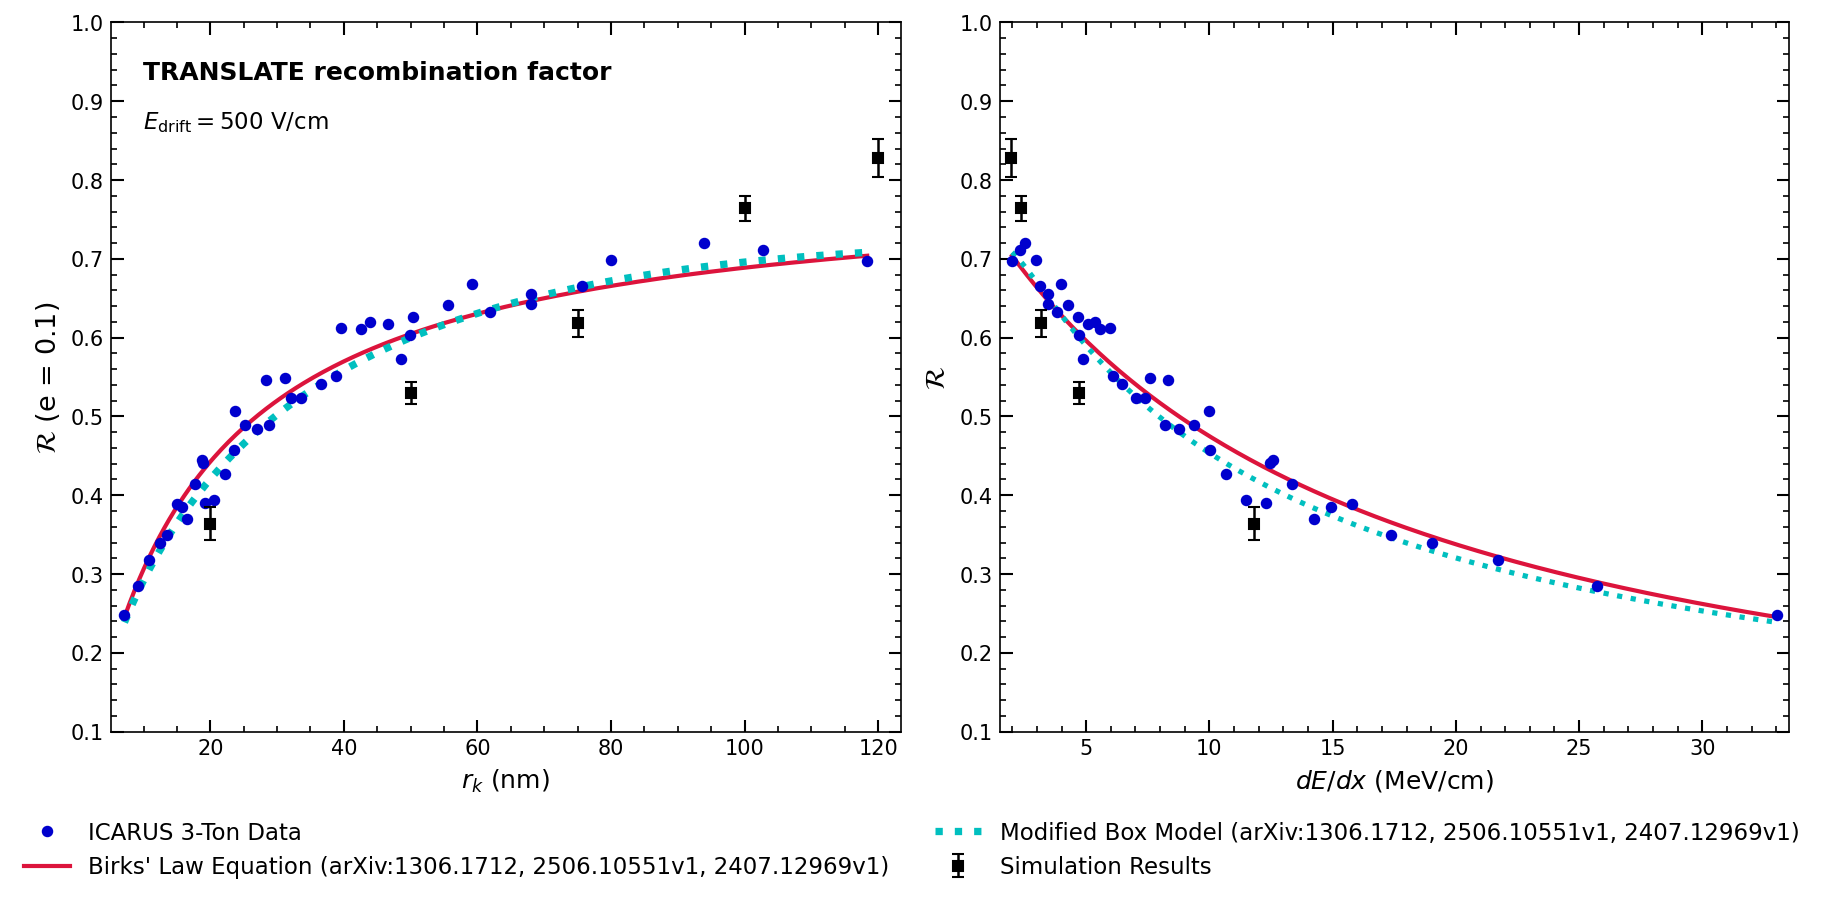

In [51]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# --- Data Load & Processing ---
# Load ICARUS data
data = np.genfromtxt('ICARUS_TPC.csv', delimiter=',')
r_k = data[:, 0]
prob = data[:, 1]

# Load Simulation data
df = pd.read_csv('5ev500vcme=0.1.csv', header=None)
r_k_500v = df.iloc[:, 0].values
prob_500v = df.iloc[:, 1:10]
mean = prob_500v.mean(axis=1).values
diff2 = (prob_500v.sub(mean, axis=0))**2
yerr = np.sqrt(diff2.mean(axis=1).values) / np.sqrt(4)

# Physical parameters
W = 23.6            # eV
E_cm = 500          # V/cm
E_nm = E_cm * 1e-7  # V/nm

def P2(r, k): 
    return 0.8 / (1.0 + (k / E_nm) * (W / r)) 

# --- Modified Box Model Parameters (ArgoNeuT arXiv:1306.1712) ---
alpha = 0.93
beta = 0.212             # (kV/cm)(g/cm^2)/MeV
rho = 1.396              # LAr density in g/cm^3
E_kV = E_cm / 1000.0     # Drift field in kV/cm
B = beta / (rho * E_kV)  # Effective Beta factor in cm/MeV

def P_ModBox_dedx(dedx):
    # R = ln(alpha + B * dE/dx) / (B * dE/dx)
    # Note: np.log in Python is the natural logarithm (ln)
    return np.log(alpha + B * dedx) / (B * dedx)

# --- Conversion Math (nm -> MeV/cm) ---
def r_to_dedx(r_nm):
    return 236.0 / r_nm

def P_ModBox_rk(r):
    # Wrapper to plot Mod Box directly against r_k
    return P_ModBox_dedx(r_to_dedx(r))

# Curve fit for Birks' Law
popt2, _ = curve_fit(P2, r_k, prob, p0=[1.0])
k_fit = popt2[0]

r_lin = np.linspace(r_k.min(), r_k.max(), 300)

# --- Plotting (Publication-Ready HEP Style) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), dpi=150)

# ==========================================
# LEFT PLOT: R vs r_k (nm)
# ==========================================
ax1.plot(r_k, prob, 'o', color='mediumblue', markersize=4.5, zorder=2, label='ICARUS 3-Ton Data')
ax1.plot(r_lin, P2(r_lin, k_fit), color='crimson', lw=2, zorder=1, label="Birks' Law Equation (arXiv:1306.1712, 2506.10551v1, 2407.12969v1)")

# Added Modified Box Model Curve (Cyan, Dotted)
ax1.plot(r_lin, P_ModBox_rk(r_lin), color='c', linestyle=':', lw=3.5, zorder=1, label="Modified Box Model (arXiv:1306.1712, 2506.10551v1, 2407.12969v1)")

ax1.errorbar(
    r_k_500v, mean, yerr=yerr, 
    fmt='s', color='black', ecolor='black',
    elinewidth=1.2, capsize=3, capthick=1, 
    markersize=5, zorder=3, label='Simulation Results'
)

ax1.set_xlabel(r'$r_k\ \text{(nm)}$', fontsize=12)
ax1.set_ylabel(r'$\mathcal{R}$ (e = 0.1)', fontsize=13)
ax1.set_xlim(r_k.min() - 2, r_k.max() + 5)

ax1.text(0.04, 0.92, 'TRANSLATE recombination factor ', transform=ax1.transAxes, fontsize=12, fontweight='bold')
ax1.text(0.04, 0.85, r'$E_{\text{drift}} = 500\text{ V/cm}$', transform=ax1.transAxes, fontsize=11)

# ==========================================
# RIGHT PLOT: R vs dE/dx (MeV/cm)
# ==========================================
dedx_lin = np.linspace(r_to_dedx(r_k.max()), r_to_dedx(r_k.min()), 300)

ax2.plot(r_to_dedx(r_k), prob, 'o', color='mediumblue', markersize=4.5, zorder=2)
ax2.plot(dedx_lin, P2(236.0 / dedx_lin, k_fit), color='crimson', lw=2, zorder=1)

# Added Modified Box Model Curve (Cyan, Dotted)
ax2.plot(dedx_lin, P_ModBox_dedx(dedx_lin), color='c', linestyle=':', lw=2.5, zorder=1)

ax2.errorbar(
    r_to_dedx(r_k_500v), mean, yerr=yerr, 
    fmt='s', color='black', ecolor='black',
    elinewidth=1.2, capsize=3, capthick=1, 
    markersize=5, zorder=3
)

ax2.set_xlabel(r'$dE/dx\ \text{(MeV/cm)}$', fontsize=12)
ax2.set_ylabel(r'$\mathcal{R}$', fontsize=13)
ax2.set_xlim(r_to_dedx(r_k.max()) - 0.5, r_to_dedx(r_k.min()) + 0.5)

# --- Global Formatting for both Axes ---
for ax in [ax1, ax2]:
    ax.set_ylim(0.1, 1.0)
    ax.minorticks_on()
    ax.tick_params(direction='in', which='both', top=True, right=True)
    ax.tick_params(direction='in', which='major', length=6, width=1, labelsize=10)
    ax.tick_params(direction='in', which='minor', length=3, width=0.8)

# Center the legend beneath the side-by-side plots (Updated to a 2x2 grid)
fig.legend(loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig('recombination_500Vcm_side_by_side.pdf', bbox_inches='tight')
plt.show()

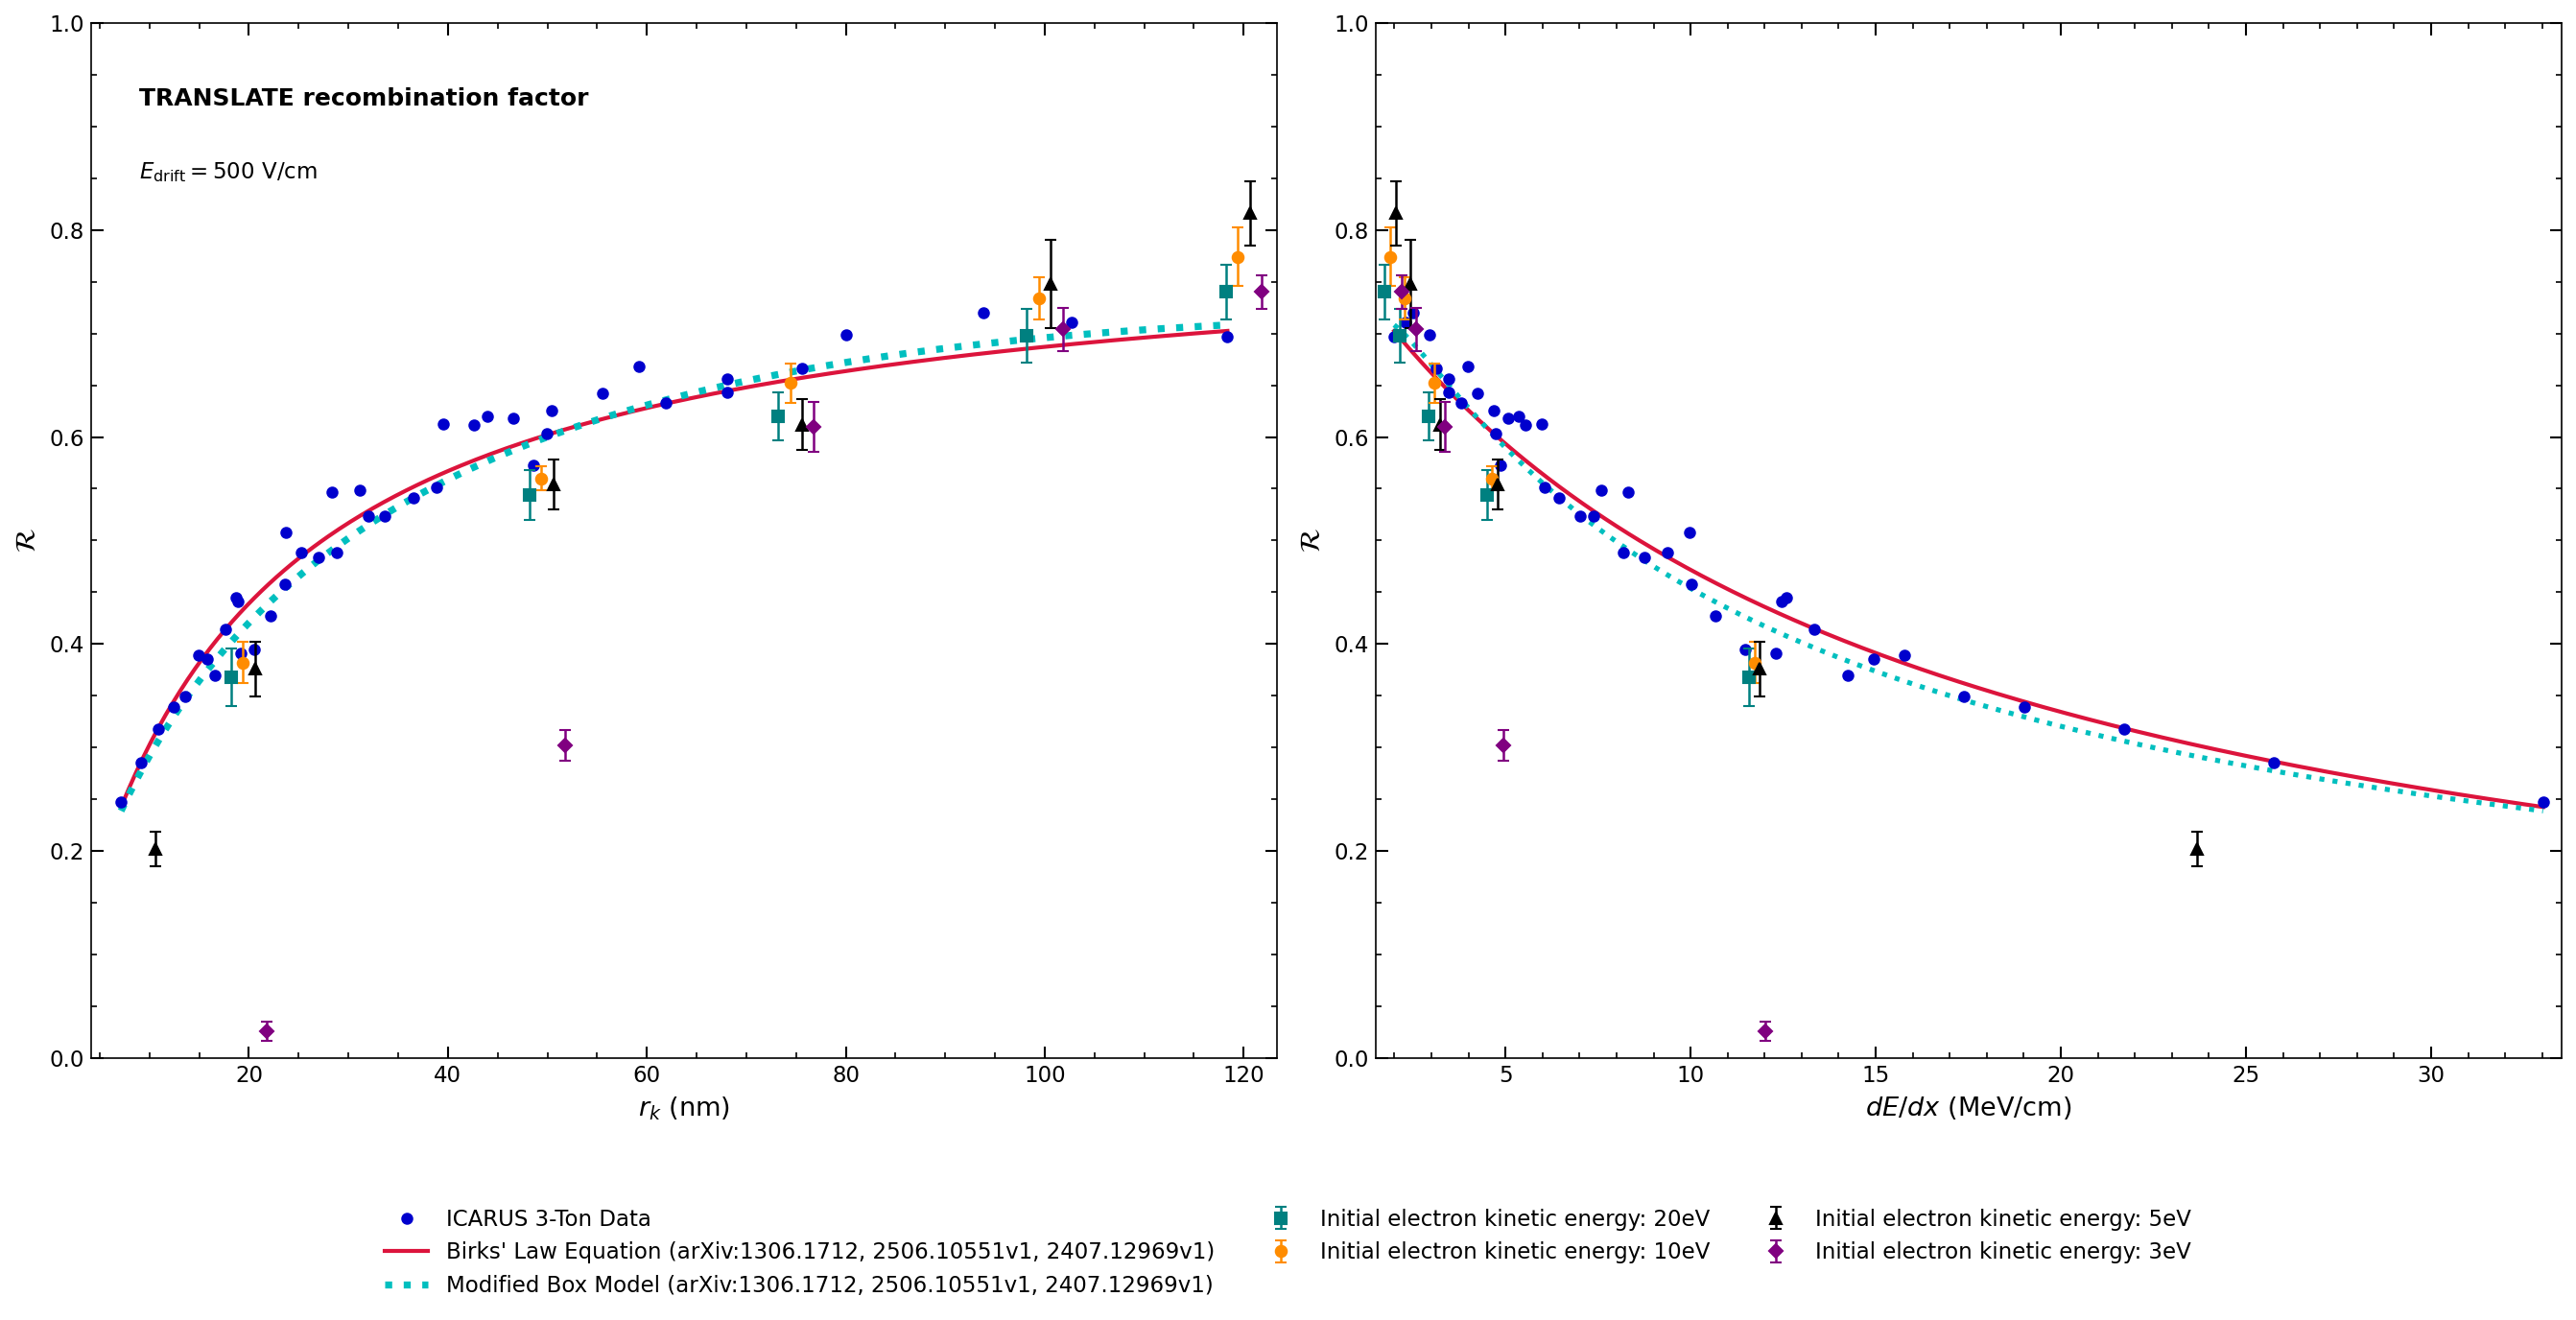

In [ ]:
# Re-establish 500 V/cm constants
W     = 23.6
E_cm  = 500
E_nm  = E_cm * 1e-7 

def P2(r, k):
    return 0.8 / (1.0 + (k / E_nm) * (W / r))

def load_stats(fname):
    df   = pd.read_csv(fname, header=None)
    r    = df.iloc[:, 0].values
    p    = df.iloc[:, 1:6]
    m    = p.mean(axis=1).values
    yerr = np.sqrt(((p.sub(m, axis=0))**2).mean(axis=1).values) / np.sqrt(4)
    return r, m, yerr

# Load data
r20, m20, e20 = load_stats('20ev500vcm.csv')
r10, m10, e10 = load_stats('10ev500vcm.csv')
r5,  m5,  e5  = load_stats('500Vcm.csv')
r3,  m3,  e3  = load_stats('3ev500vcm.csv')

r_lin = np.linspace(r_k.min(), r_k.max(), 300)

# --- Conversion Math (nm -> MeV/cm) ---
def r_to_dedx(r_nm):
    """Converts track spacing in nm to dE/dx in MeV/cm"""
    return 236.0 / r_nm

# --- Plotting (Publication-Ready HEP Style) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8), dpi=150)

# ==========================================
# LEFT PLOT: R vs r_k (nm)
# ==========================================
offset = 1.2  # nm shift to separate error bars

ax1.plot(r_k, prob, 'o', color='mediumblue', markersize=5, zorder=2, label='ICARUS 3-Ton Data')
ax1.plot(r_lin, P2(r_lin, k), '-', color='crimson', lw=2, zorder=1, label="Birks' Law Equation (arXiv:1306.1712, 2506.10551v1, 2407.12969v1)")
ax1.plot(r_lin, P_ModBox_rk(r_lin), color='c', linestyle=':', lw=3.5, zorder=1, label="Modified Box Model (arXiv:1306.1712, 2506.10551v1, 2407.12969v1)")

ax1.errorbar(r20 - offset*1.5, m20, yerr=e20, fmt='s', color='teal', elinewidth=1.2, capsize=3, markersize=5.5, label='Initial electron kinetic energy: 20eV')
ax1.errorbar(r10 - offset*0.5, m10, yerr=e10, fmt='o', color='darkorange', elinewidth=1.2, capsize=3, markersize=5.5, label='Initial electron kinetic energy: 10eV')
ax1.errorbar(r5 + offset*0.5,  m5,  yerr=e5,  fmt='^', color='black', elinewidth=1.2, capsize=3, markersize=6, label='Initial electron kinetic energy: 5eV')
ax1.errorbar(r3 + offset*1.5,  m3,  yerr=e3,  fmt='D', color='purple', elinewidth=1.2, capsize=3, markersize=5, label='Initial electron kinetic energy: 3eV')

ax1.set_xlabel(r'$r_k\ (\mathrm{nm})$', fontsize=13)
ax1.set_ylabel(r'$\mathcal{R}$', fontsize=14)
ax1.set_xlim(r_k.min() - 3, r_k.max() + 5)
ax1.text(0.04, 0.92, 'TRANSLATE recombination factor', transform=ax1.transAxes, fontsize=12, fontweight='bold')
ax1.text(0.04, 0.85, r'$E_{\text{drift}} = 500\ \text{V/cm}$', transform=ax1.transAxes, fontsize=11)

# ==========================================
# RIGHT PLOT: R vs dE/dx (MeV/cm)
# ==========================================
dedx_offset = 0.15 # MeV/cm shift to separate error bars

ax2.plot(r_to_dedx(r_k), prob, 'o', color='mediumblue', markersize=5, zorder=2)

# Generate smooth linspace for dE/dx specifically so the line connects properly
dedx_lin = np.linspace(r_to_dedx(r_k.max()), r_to_dedx(r_k.min()), 300)
ax2.plot(dedx_lin, P2(236.0/dedx_lin, k), '-', color='crimson', lw=2, zorder=1)
ax2.plot(dedx_lin, P_ModBox_dedx(dedx_lin), color='c', linestyle=':', lw=2.5, zorder=1)
ax2.errorbar(r_to_dedx(r20) - dedx_offset*1.5, m20, yerr=e20, fmt='s', color='teal', elinewidth=1.2, capsize=3, markersize=5.5)
ax2.errorbar(r_to_dedx(r10) - dedx_offset*0.5, m10, yerr=e10, fmt='o', color='darkorange', elinewidth=1.2, capsize=3, markersize=5.5)
ax2.errorbar(r_to_dedx(r5)  + dedx_offset*0.5, m5,  yerr=e5,  fmt='^', color='black', elinewidth=1.2, capsize=3, markersize=6)
ax2.errorbar(r_to_dedx(r3)  + dedx_offset*1.5, m3,  yerr=e3,  fmt='D', color='purple', elinewidth=1.2, capsize=3, markersize=5)

ax2.set_xlabel(r'$dE/dx\ (\mathrm{MeV/cm})$', fontsize=13)
ax2.set_ylabel(r'$\mathcal{R}$', fontsize=14)
ax2.set_xlim(r_to_dedx(r_k.max()) - 0.5, r_to_dedx(r_k.min()) + 0.5)

# --- Global Formatting for both Axes ---
for ax in [ax1, ax2]:
    ax.set_ylim(0.0, 1.0)
    ax.minorticks_on()
    ax.tick_params(direction='in', which='both', top=True, right=True)
    ax.tick_params(direction='in', which='major', length=6, width=1, labelsize=11)
    ax.tick_params(direction='in', which='minor', length=3, width=0.8)

# Legend placed on the right plot
fig.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig('recombination_side_by_side.pdf', bbox_inches='tight')
plt.show()


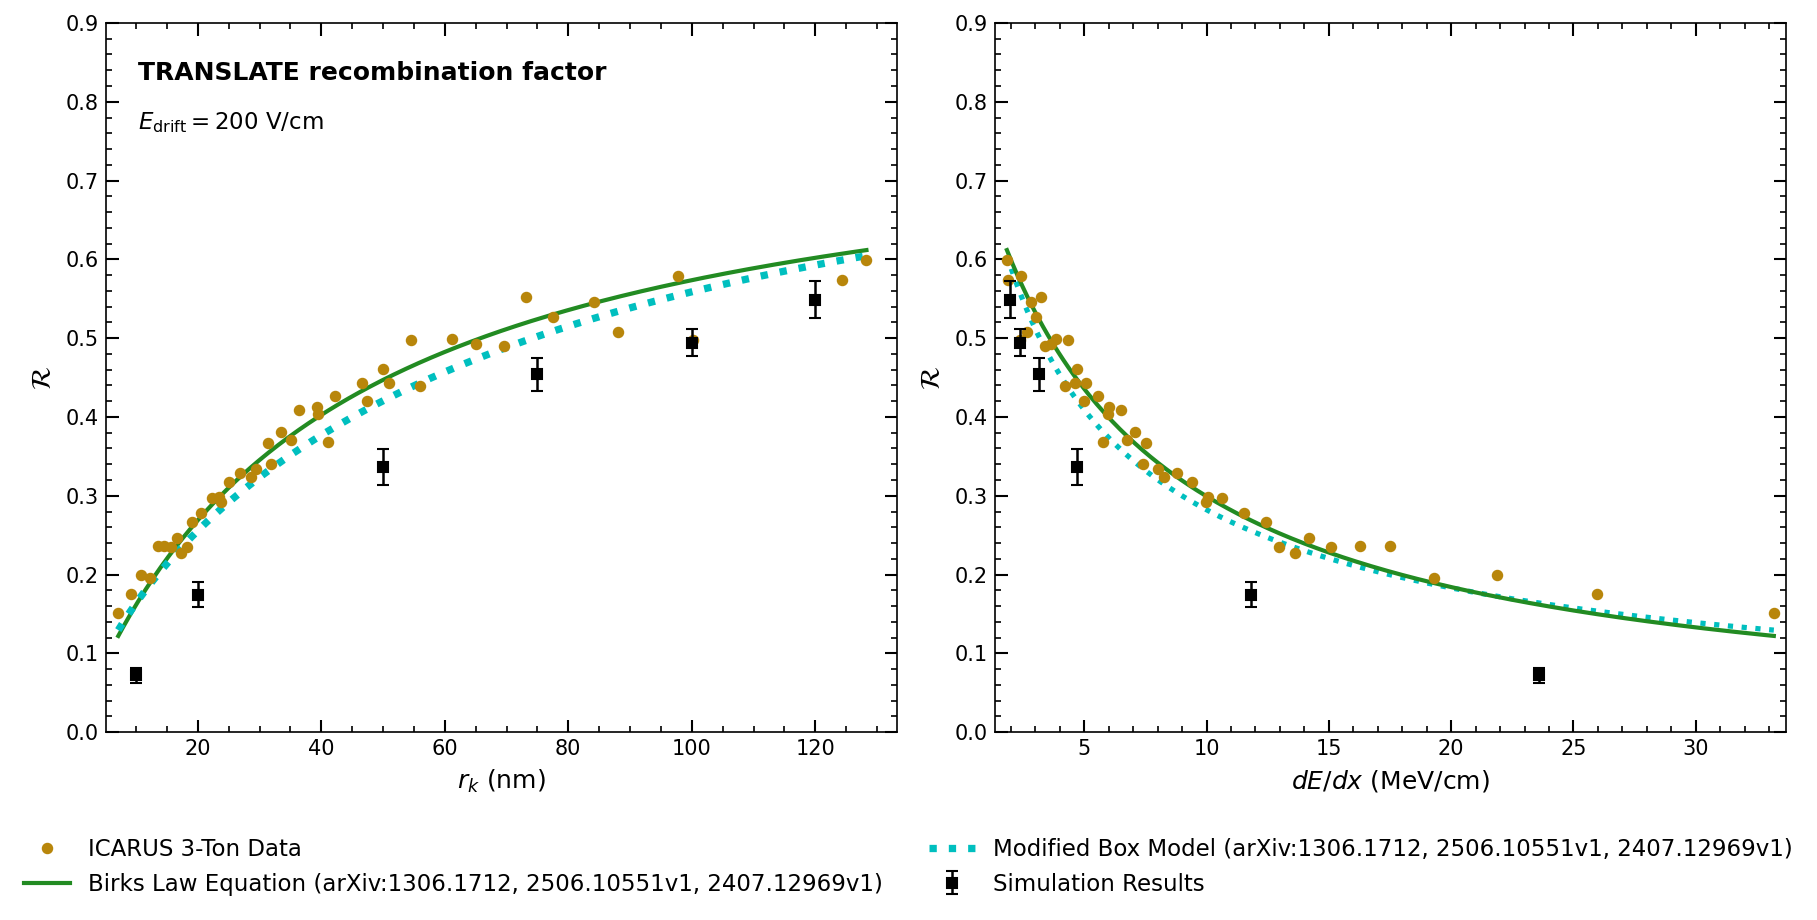

In [53]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# --- Data Load & Processing ---
# Load ICARUS data
data = np.genfromtxt('ICARUS_TPC_200V.csv', delimiter=',')
r_k = data[:, 0]
prob = data[:, 1]

# Load Simulation data
df = pd.read_csv('200Vcm.csv', delimiter=',', header=None)
r_k_200v = df.iloc[:, 0].values
prob_200v = df.iloc[:, 1:10]

mean = prob_200v.mean(axis=1).values
diff2 = (prob_200v.sub(mean, axis=0))**2
yerr = np.sqrt(diff2.mean(axis=1).values) / np.sqrt(9)

# Physical Parameters
W = 23.6            # eV
E_cm = 200          # V/cm
E_nm = E_cm * 1e-7  # V/nm

def P2(r, k):
    return 0.8 / (1.0 + (k / E_nm) * (W / r))

popt2, _ = curve_fit(P2, r_k, prob, p0=[1.0])
k_fit = popt2[0]

r_lin = np.linspace(r_k.min(), r_k.max(), 300)

# --- Modified Box Model Parameters (ArgoNeuT arXiv:1306.1712) ---
alpha = 0.93
beta = 0.212             # (kV/cm)(g/cm^2)/MeV
rho = 1.396              # LAr density in g/cm^3
E_kV = E_cm / 1000.0     # Drift field in kV/cm
B = beta / (rho * E_kV)  # Effective Beta factor in cm/MeV

def P_ModBox_dedx(dedx):
    # R = ln(alpha + B * dE/dx) / (B * dE/dx)
    return np.log(alpha + B * dedx) / (B * dedx)

# --- Conversion Math (nm -> MeV/cm) ---
def r_to_dedx(r_nm):
    return 236.0 / r_nm

def P_ModBox_rk(r):
    # Wrapper to plot Mod Box directly against r_k
    return P_ModBox_dedx(r_to_dedx(r))

# --- Plotting (Publication-Ready HEP Style) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), dpi=150)

# ==========================================
# LEFT PLOT: R vs r_k (nm)
# ==========================================
ax1.plot(r_k, prob, 'o', color='darkgoldenrod', markersize=4.5, zorder=2, label='ICARUS 3-Ton Data')
ax1.plot(r_lin, P2(r_lin, k_fit), color='forestgreen', lw=2, zorder=1, label="Birks Law Equation (arXiv:1306.1712, 2506.10551v1, 2407.12969v1)")
ax1.plot(r_lin, P_ModBox_rk(r_lin), color='c', linestyle=':', lw=3.5, zorder=1, label="Modified Box Model (arXiv:1306.1712, 2506.10551v1, 2407.12969v1)")
ax1.errorbar(
    r_k_200v, mean, yerr=yerr, 
    fmt='s', color='black', ecolor='black',
    elinewidth=1.2, capsize=3, capthick=1, 
    markersize=5, zorder=3, label='Simulation Results'
)

ax1.set_xlabel(r'$r_k\ \text{(nm)}$', fontsize=12)
ax1.set_ylabel(r'$\mathcal{R}$', fontsize=13)
ax1.set_xlim(r_k.min() - 2, r_k.max() + 5)

ax1.text(0.04, 0.92, 'TRANSLATE recombination factor', transform=ax1.transAxes, fontsize=12, fontweight='bold')
ax1.text(0.04, 0.85, r'$E_{\text{drift}} = 200\text{ V/cm}$', transform=ax1.transAxes, fontsize=11)

# ==========================================
# RIGHT PLOT: R vs dE/dx (MeV/cm)
# ==========================================
dedx_lin = np.linspace(r_to_dedx(r_k.max()), r_to_dedx(r_k.min()), 300)

ax2.plot(r_to_dedx(r_k), prob, 'o', color='darkgoldenrod', markersize=4.5, zorder=2)
ax2.plot(dedx_lin, P_ModBox_dedx(dedx_lin), color='c', linestyle=':', lw=2.5, zorder=1)
ax2.plot(dedx_lin, P2(236.0 / dedx_lin, k_fit), color='forestgreen', lw=2, zorder=1)
ax2.errorbar(
    r_to_dedx(r_k_200v), mean, yerr=yerr, 
    fmt='s', color='black', ecolor='black',
    elinewidth=1.2, capsize=3, capthick=1, 
    markersize=5, zorder=3
)

ax2.set_xlabel(r'$dE/dx\ \text{(MeV/cm)}$', fontsize=12)
ax2.set_ylabel(r'$\mathcal{R}$', fontsize=13)
ax2.set_xlim(r_to_dedx(r_k.max()) - 0.5, r_to_dedx(r_k.min()) + 0.5)

# --- Global Formatting for both Axes ---
for ax in [ax1, ax2]:
    ax.set_ylim(0.0, 0.9) 
    ax.minorticks_on()
    ax.tick_params(direction='in', which='both', top=True, right=True)
    ax.tick_params(direction='in', which='major', length=6, width=1, labelsize=10)
    ax.tick_params(direction='in', which='minor', length=3, width=0.8)

# --- FIXED LEGEND ---
# Changed to ncol=2 and adjusted the bounding box anchor to -0.12 so the long labels fit cleanly
fig.legend(loc='lower center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig('recombination_200Vcm_side_by_side.pdf', bbox_inches='tight')
plt.show()

## Recombination Plots with Angular Dependency

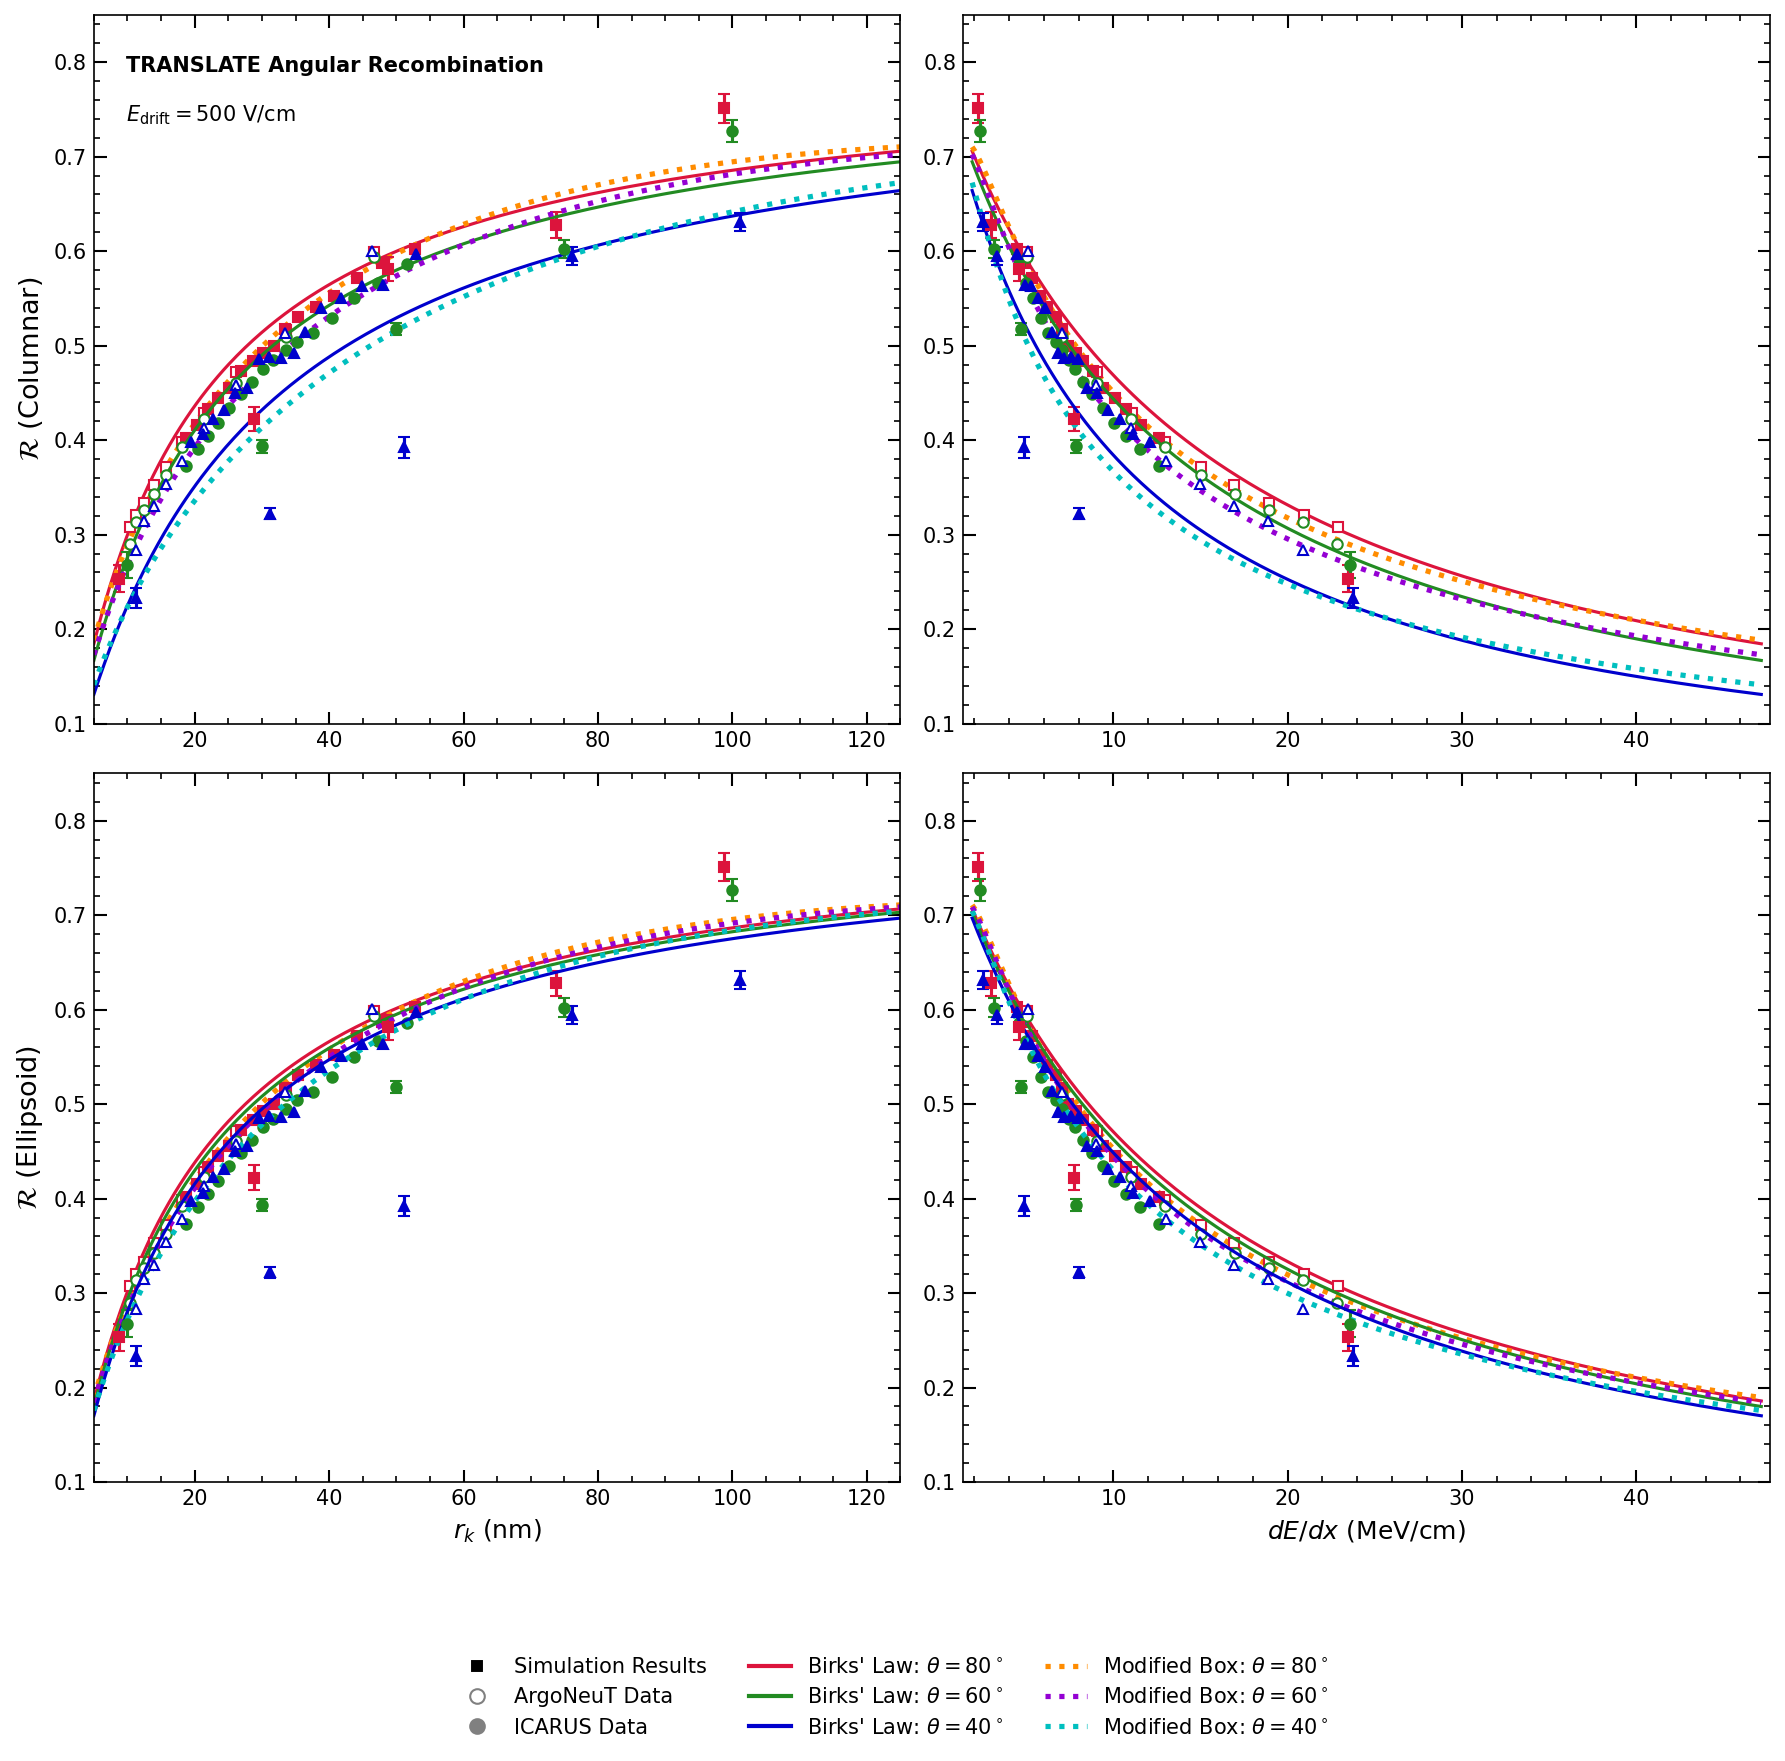

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.gridspec as gridspec

# ==========================================
# 1. PARAMETERS & FUNCTIONS
# ==========================================
W = 23.6            # eV
E_cm = 500          # V/cm
E_nm = E_cm * 1e-7  # V/nm
k_val = 4.86e-5 / 1.396  

# Modified Box Parameters
alpha = 0.93
beta_90 = 0.212
rho = 1.396
E_kV = E_cm / 1000.0

def P_ellipsoid(r, ang):
    rad = np.deg2rad(ang)
    eff_E = E_nm * np.sqrt((np.sin(rad))**2 + (np.cos(rad)/1.25)**2)
    return 0.8 / (1.0 + (k_val / eff_E) * (W / r))

def P_columnar(r, ang):
    rad = np.deg2rad(ang)
    eff_E = E_nm * np.sin(rad)
    return 0.8 / (1.0 + (k_val / eff_E) * (W / r))

# Modified Box Models (B_phi calculation)
def B_columnar(ang):
    rad = np.deg2rad(ang)
    beta_phi = beta_90 / np.sin(rad)
    return beta_phi / (rho * E_kV)

def B_ellipsoid(ang):
    rad = np.deg2rad(ang)
    beta_phi = beta_90 / np.sqrt((np.sin(rad))**2 + (np.cos(rad)/1.25)**2)
    return beta_phi / (rho * E_kV)

def ModBox_R(dedx, B_val):
    return np.log(alpha + B_val * dedx) / (B_val * dedx)

def r_to_dedx(r_nm):
    return 236.0 / r_nm

def dedx_to_r(dedx):
    return 236.0 / dedx

# ==========================================
# 2. DATA LOADING
# ==========================================
def load_sim(fname):
    df = pd.read_csv(fname, header=None)
    r = df.iloc[:, 0].values
    p = df.iloc[:, 1:10]
    m = p.mean(axis=1).values
    yerr = np.sqrt(((p.sub(m, axis=0))**2).mean(axis=1).values) / np.sqrt(9)
    return r, m, yerr

def load_argo(fname):
    data = np.genfromtxt(fname, delimiter=',')
    data = data[data[:, 0].argsort()] 
    dedx_mev = data[:, 0]
    dqdx_k = data[:, 1]
    R = (dqdx_k * 23.6) / (dedx_mev * 1000)
    r_k = dedx_to_r(dedx_mev)
    return r_k, dedx_mev, R

def load_icarus(fname):
    data = np.genfromtxt(fname, delimiter=',')
    data = data[data[:, 0].argsort()] 
    dedx_mev = data[:, 0]
    dqdx_adc = data[:, 1]
    
    # Unit Conversions: ADC/cm -> e/cm -> R
    dqdx_e = dqdx_adc * 75.0
    R = (dqdx_e * 23.6) / (dedx_mev * 1e6)
    r_k = dedx_to_r(dedx_mev)
    return r_k, dedx_mev, R

sim_data = {
    80: load_sim('500vcm80deg.csv'),
    60: load_sim('500vcm60deg.csv'),
    40: load_sim('500vcm40deg.csv')
}

argo_data = {
    80: load_argo('ARGONEUT_80deg.csv'),
    60: load_argo('ARGONEUT_60deg.csv'),
    40: load_argo('ARGONEUT_40deg.csv')
}

icarus_data = {
    80: load_icarus('ICARUS_80deg.csv'),
    60: load_icarus('ICARUS_60deg.csv'),
    40: load_icarus('ICARUS_40deg.csv')
}

angles = [80, 60, 40]

# --- Color Dictionaries ---
colors_birks = {80: 'crimson', 60: 'forestgreen', 40: 'mediumblue'}
colors_modbox = {80: 'darkorange', 60: 'darkviolet', 40: 'c'}

markers = {80: 's', 60: 'o', 40: '^'}
offset_rk = {80: -1.2, 60: 0.0, 40: 1.2}
offset_dedx = {80: -0.15, 60: 0.0, 40: 0.15}

r_lin = np.linspace(5, 125, 300)
dedx_lin = np.linspace(r_to_dedx(125), r_to_dedx(5), 300)

def format_hep_axes(ax):
    ax.minorticks_on()
    ax.tick_params(direction='in', which='both', top=True, right=True)
    ax.tick_params(direction='in', which='major', length=6, width=1)
    ax.tick_params(direction='in', which='minor', length=3, width=0.8)

# ==========================================
# 3. FIGURE GENERATION
# ==========================================
fig1, axs1 = plt.subplots(2, 2, figsize=(12, 10.5), dpi=150) # Slightly taller to fit the 3-row legend
(ax_c_r, ax_c_d), (ax_e_r, ax_e_d) = axs1

for ang in angles:
    c_birks = colors_birks[ang]
    c_mod = colors_modbox[ang]
    m = markers[ang]
    
    # Extract data
    r_sim, prob_sim, err_sim = sim_data[ang]
    r_argo, d_argo, prob_argo = argo_data[ang]
    r_ica, d_ica, prob_ica = icarus_data[ang]
    
    B_col = B_columnar(ang)
    B_ell = B_ellipsoid(ang)
    
    # ------------------------------------------
    # ROW 0: COLUMNAR MODEL
    # ------------------------------------------
    # Theoretical Fits
    ax_c_r.plot(r_lin, P_columnar(r_lin, ang), '-', color=c_birks, lw=1.5)
    ax_c_d.plot(dedx_lin, P_columnar(236.0/dedx_lin, ang), '-', color=c_birks, lw=1.5)
    
    # Modified Box (using new colors)
    ax_c_r.plot(r_lin, ModBox_R(r_to_dedx(r_lin), B_col), ':', color=c_mod, lw=2.5)
    ax_c_d.plot(dedx_lin, ModBox_R(dedx_lin, B_col), ':', color=c_mod, lw=2.5)
    
    # Data Placements (Data markers match the Birks color family for continuity)
    ax_c_r.errorbar(r_sim + offset_rk[ang], prob_sim, yerr=err_sim, fmt=m, color=c_birks, ecolor=c_birks, capsize=3, markersize=5)
    ax_c_d.errorbar(r_to_dedx(r_sim) + offset_dedx[ang], prob_sim, yerr=err_sim, fmt=m, color=c_birks, ecolor=c_birks, capsize=3, markersize=5)
    
    ax_c_r.plot(r_argo, prob_argo, m, color=c_birks, markerfacecolor='white', markersize=5)
    ax_c_d.plot(d_argo, prob_argo, m, color=c_birks, markerfacecolor='white', markersize=5)
    
    ax_c_r.plot(r_ica, prob_ica, m, color=c_birks, markerfacecolor=c_birks, markersize=5)
    ax_c_d.plot(d_ica, prob_ica, m, color=c_birks, markerfacecolor=c_birks, markersize=5)

    # ------------------------------------------
    # ROW 1: ELLIPSOID MODEL
    # ------------------------------------------
    # Theoretical Fits
    ax_e_r.plot(r_lin, P_ellipsoid(r_lin, ang), '-', color=c_birks, lw=1.5)
    ax_e_d.plot(dedx_lin, P_ellipsoid(236.0/dedx_lin, ang), '-', color=c_birks, lw=1.5)
    
    # Modified Box (using new colors)
    ax_e_r.plot(r_lin, ModBox_R(r_to_dedx(r_lin), B_ell), ':', color=c_mod, lw=2.5)
    ax_e_d.plot(dedx_lin, ModBox_R(dedx_lin, B_ell), ':', color=c_mod, lw=2.5)
    
    # Data Placements
    ax_e_r.errorbar(r_sim + offset_rk[ang], prob_sim, yerr=err_sim, fmt=m, color=c_birks, ecolor=c_birks, capsize=3, markersize=5)
    ax_e_d.errorbar(r_to_dedx(r_sim) + offset_dedx[ang], prob_sim, yerr=err_sim, fmt=m, color=c_birks, ecolor=c_birks, capsize=3, markersize=5)
    
    ax_e_r.plot(r_argo, prob_argo, m, color=c_birks, markerfacecolor='white', markersize=5)
    ax_e_d.plot(d_argo, prob_argo, m, color=c_birks, markerfacecolor='white', markersize=5)
    
    ax_e_r.plot(r_ica, prob_ica, m, color=c_birks, markerfacecolor=c_birks, markersize=5)
    ax_e_d.plot(d_ica, prob_ica, m, color=c_birks, markerfacecolor=c_birks, markersize=5)

# Formatting Fig 1
for ax in axs1.flat:
    format_hep_axes(ax)
    ax.set_ylim(0.1, 0.85)

ax_c_r.set_xlim(5, 125)
ax_e_r.set_xlim(5, 125)
ax_c_d.set_xlim(r_to_dedx(125)-0.5, r_to_dedx(5)+0.5)
ax_e_d.set_xlim(r_to_dedx(125)-0.5, r_to_dedx(5)+0.5)

ax_e_r.set_xlabel(r'$r_k\ (\mathrm{nm})$', fontsize=12)
ax_e_d.set_xlabel(r'$dE/dx\ (\mathrm{MeV/cm})$', fontsize=12)
ax_c_r.set_ylabel(r'$\mathcal{R}$ (Columnar)', fontsize=13)
ax_e_r.set_ylabel(r'$\mathcal{R}$ (Ellipsoid)', fontsize=13)

ax_c_r.text(0.04, 0.92, 'TRANSLATE Angular Recombination', transform=ax_c_r.transAxes, fontweight='bold')
ax_c_r.text(0.04, 0.85, r'$E_{\text{drift}} = 500\ \text{V/cm}$', transform=ax_c_r.transAxes)

# --- Expanded 3x3 Legend ---
leg_elements1 = [
    # Row 1: Datasets
    Line2D([0], [0], marker='s', color='w', markerfacecolor='black', markersize=7, label='Simulation Results'),
    Line2D([0], [0], marker='o', color='w', markeredgecolor='gray', markerfacecolor='white', markersize=7, label='ArgoNeuT Data'),
    Line2D([0], [0], marker='o', color='w', markeredgecolor='gray', markerfacecolor='gray', markersize=7, label='ICARUS Data'),
    
    # Row 2: Birks' Law Curves
    Line2D([0], [0], linestyle='-', color='crimson', lw=2, label=r"Birks' Law: $\theta = 80^\circ$"),
    Line2D([0], [0], linestyle='-', color='forestgreen', lw=2, label=r"Birks' Law: $\theta = 60^\circ$"),
    Line2D([0], [0], linestyle='-', color='mediumblue', lw=2, label=r"Birks' Law: $\theta = 40^\circ$"),
    
    # Row 3: Modified Box Curves
    Line2D([0], [0], linestyle=':', color='darkorange', lw=2.5, label=r"Modified Box: $\theta = 80^\circ$"),
    Line2D([0], [0], linestyle=':', color='darkviolet', lw=2.5, label=r"Modified Box: $\theta = 60^\circ$"),
    Line2D([0], [0], linestyle=':', color='c', lw=2.5, label=r"Modified Box: $\theta = 40^\circ$")
]

# Adjusted bounding box to -0.12 to accommodate the third row of text
fig1.legend(handles=leg_elements1, loc='lower center', bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
fig1.tight_layout()
plt.show()

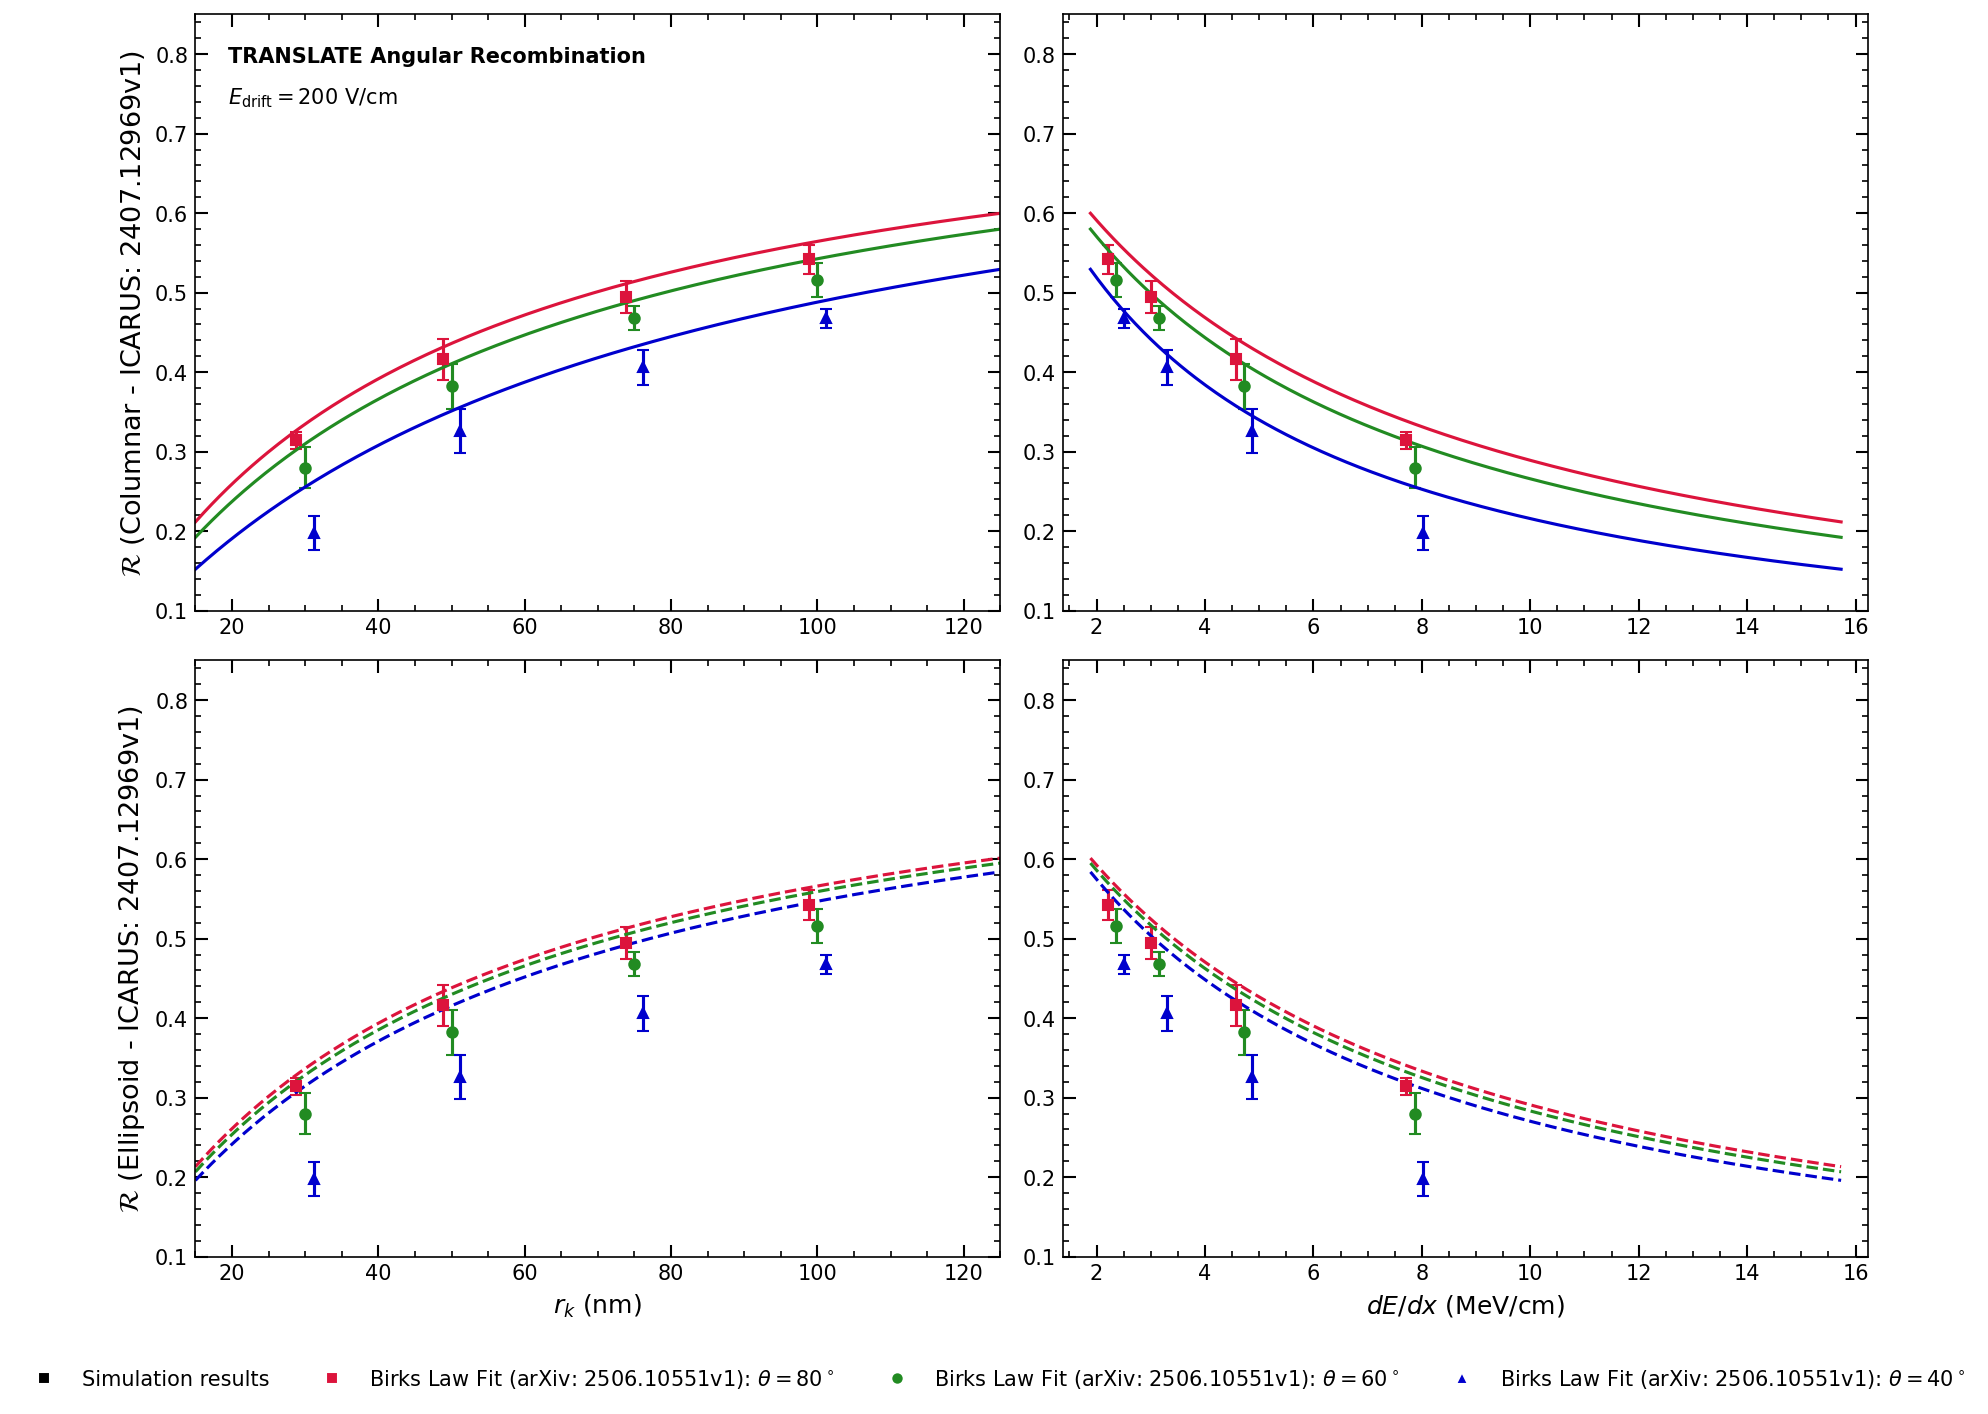

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==========================================
# 1. PARAMETERS & FUNCTIONS
# ==========================================
W = 23.6            # eV
E_cm = 200          # V/cm  <-- Updated to 200
E_nm = E_cm * 1e-7  # V/nm

# Assuming the global Birks parameter k remains the same 
# (Update if your 200V/cm specific fit yields a different k)
k_val = 4.86e-5 / 1.396  

def P_ellipsoid(r, ang):
    rad = np.deg2rad(ang)
    eff_E = E_nm * np.sqrt((np.sin(rad))**2 + (np.cos(rad)/1.25)**2)
    return 0.8 / (1.0 + (k_val / eff_E) * (W / r))

def P_columnar(r, ang):
    rad = np.deg2rad(ang)
    eff_E = E_nm * np.sin(rad)
    return 0.8 / (1.0 + (k_val / eff_E) * (W / r))

def r_to_dedx(r_nm):
    return 236.0 / r_nm

def load_sim(fname):
    df = pd.read_csv(fname, header=None)
    r = df.iloc[:, 0].values
    p = df.iloc[:, 1:6]
    m = p.mean(axis=1).values
    yerr = np.sqrt(((p.sub(m, axis=0))**2).mean(axis=1).values) / np.sqrt(4)
    return r, m, yerr

# ==========================================
# 2. LOAD DATA
# ==========================================
# Be sure to update these CSV filenames to your 200 V/cm angular data files
sim_data = {
    80: load_sim('200vcm80deg.csv'),
    60: load_sim('200vcm60deg.csv'),
    40: load_sim('200vcm40deg.csv')
}

angles = [80, 60, 40]
# Colors are kept identical to the 500 V/cm plot for visual consistency
colors = {80: 'crimson', 60: 'forestgreen', 40: 'mediumblue'}
markers = {80: 's', 60: 'o', 40: '^'}

offset_rk = {80: -1.2, 60: 0.0, 40: 1.2}
offset_dedx = {80: -0.15, 60: 0.0, 40: 0.15}

r_lin = np.linspace(15, 125, 300)
dedx_lin = np.linspace(r_to_dedx(125), r_to_dedx(15), 300)

def format_hep_axes(ax):
    ax.minorticks_on()
    ax.tick_params(direction='in', which='both', top=True, right=True)
    ax.tick_params(direction='in', which='major', length=6, width=1)
    ax.tick_params(direction='in', which='minor', length=3, width=0.8)

# ==========================================
# FIGURE 1: 2x2 GRID (Separated Models)
# ==========================================
fig1, axs1 = plt.subplots(2, 2, figsize=(12, 9), dpi=150)
(ax_c_r, ax_c_d), (ax_e_r, ax_e_d) = axs1

for ang in angles:
    c, m = colors[ang], markers[ang]
    r_sim, prob_sim, err_sim = sim_data[ang]
    
    # -- Row 0: Columnar Model --
    ax_c_r.plot(r_lin, P_columnar(r_lin, ang), '-', color=c, lw=1.5)
    ax_c_d.plot(dedx_lin, P_columnar(236.0/dedx_lin, ang), '-', color=c, lw=1.5)
    
    ax_c_r.errorbar(r_sim + offset_rk[ang], prob_sim, yerr=err_sim, fmt=m, color=c, ecolor=c, capsize=3, markersize=5)
    ax_c_d.errorbar(r_to_dedx(r_sim) + offset_dedx[ang], prob_sim, yerr=err_sim, fmt=m, color=c, ecolor=c, capsize=3, markersize=5)

    # -- Row 1: Ellipsoid Model --
    ax_e_r.plot(r_lin, P_ellipsoid(r_lin, ang), '--', color=c, lw=1.5)
    ax_e_d.plot(dedx_lin, P_ellipsoid(236.0/dedx_lin, ang), '--', color=c, lw=1.5)
    
    ax_e_r.errorbar(r_sim + offset_rk[ang], prob_sim, yerr=err_sim, fmt=m, color=c, ecolor=c, capsize=3, markersize=5)
    ax_e_d.errorbar(r_to_dedx(r_sim) + offset_dedx[ang], prob_sim, yerr=err_sim, fmt=m, color=c, ecolor=c, capsize=3, markersize=5)

# Formatting Fig 1
for ax in axs1.flat:
    format_hep_axes(ax)
    ax.set_ylim(0.1, 0.85)

ax_c_r.set_xlim(15, 125)
ax_e_r.set_xlim(15, 125)
ax_c_d.set_xlim(r_to_dedx(125)-0.5, r_to_dedx(15)+0.5)
ax_e_d.set_xlim(r_to_dedx(125)-0.5, r_to_dedx(15)+0.5)

ax_e_r.set_xlabel(r'$r_k\ (\mathrm{nm})$', fontsize=12)
ax_e_d.set_xlabel(r'$dE/dx\ (\mathrm{MeV/cm})$', fontsize=12)
ax_c_r.set_ylabel(r'$\mathcal{R}$ (Columnar - ICARUS: 2407.12969v1)', fontsize=13)
ax_e_r.set_ylabel(r'$\mathcal{R}$ (Ellipsoid - ICARUS: 2407.12969v1)', fontsize=13)

ax_c_r.text(0.04, 0.92, 'TRANSLATE Angular Recombination', transform=ax_c_r.transAxes, fontweight='bold')
ax_c_r.text(0.04, 0.85, r'$E_{\text{drift}} = 200\ \text{V/cm}$', transform=ax_c_r.transAxes)

# Legend Fig 1 (ArgoNeuT removed, centered correctly)
leg_elements1 = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor='black', markersize=6, label='Simulation results'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='crimson', markersize=6, label=r'Birks Law Fit (arXiv: 2506.10551v1): $\theta = 80^\circ$'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='forestgreen', markersize=6, label=r'Birks Law Fit (arXiv: 2506.10551v1): $\theta = 60^\circ$'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='mediumblue', markersize=6, label=r'Birks Law Fit (arXiv: 2506.10551v1): $\theta = 40^\circ$')
]
fig1.legend(handles=leg_elements1, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=4, frameon=False)
fig1.tight_layout()

# Save and Show
plt.savefig('angular_recombination_200vcm_2x2.pdf', bbox_inches='tight')
plt.show()